# 正常復元の必要性とα・重みの学習

研究報告の8枚目に使う模式図です。正常の復元に必要な成分と不要な成分で、復元損失と専用正則化がどのように働くかを対比します。

- **必要な成分**：強く揺らすと復元誤差が増えやすく、復元損失がαの増加に対抗します。
- **不要な成分**：揺らしても復元への影響が小さければ、専用正則化によってαを大きくしやすく、その成分への依存を弱める方向にデコーダの重みも学習します。
- αを先に決め、その後に重みを学ぶという手順ではありません。α・エンコーダ・デコーダは**同じ損失で同時に更新**します。
- αは相対ノイズであり、重要度の直接の測定値ではありません。必要性を人が指定するわけでもありません。
- 図は働く方向の概念説明で、αや重みが常に単調に変化することや、異常除去・性能改善を保証しません。

出典：[Senellart et al., 2026, 第5.2節](https://arxiv.org/html/2605.02918v1#S5.SS2)、[著者指定MultiVaeの分散・専用正則化](https://github.com/AgatheSenellart/MultiVae/blob/0df7a0d64be66e8ee95990e5ea98deaa6f3d1697/src/multivae/models/base/base_utils.py)。学習済みモデルの実測結果ではありません。

「すべて実行」でPNG・SVGを `reports/sparse_vae_theory/figures/` に保存します。元のノートブック・モデル・データは変更しません。

In [1]:
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display
from PIL import Image
import xml.etree.ElementTree as ET

ROOT=next((p for p in (Path.cwd(),*Path.cwd().parents) if (p/'memory/memory.md').is_file()),None)
if ROOT is None:raise FileNotFoundError('リポジトリ内で実行してください。')
OUT=ROOT/'reports/sparse_vae_theory/figures';OUT.mkdir(parents=True,exist_ok=True)
STEM='10_復元の必要性とαの学習'
np.random.seed(42)  # この図は乱数を使わないが、再現用の設定を固定
available={f.name for f in font_manager.fontManager.ttflist}
FONT=next((f for f in ['Meiryo','Yu Gothic','Noto Sans CJK JP','IPAexGothic'] if f in available),'DejaVu Sans')
plt.rcParams.update({'font.family':FONT,'font.size':21,'svg.fonttype':'path','axes.unicode_minus':False,
                     'figure.facecolor':'white','savefig.facecolor':'white','svg.hashsalt':'sparse-vae-necessary-20261029'})
C={'ink':'#2e2b21','muted':'#605b4f','teal':'#287c80','olive':'#777744','red':'#b45342','pale':'#eef4f3','sand':'#f1f0e6'}

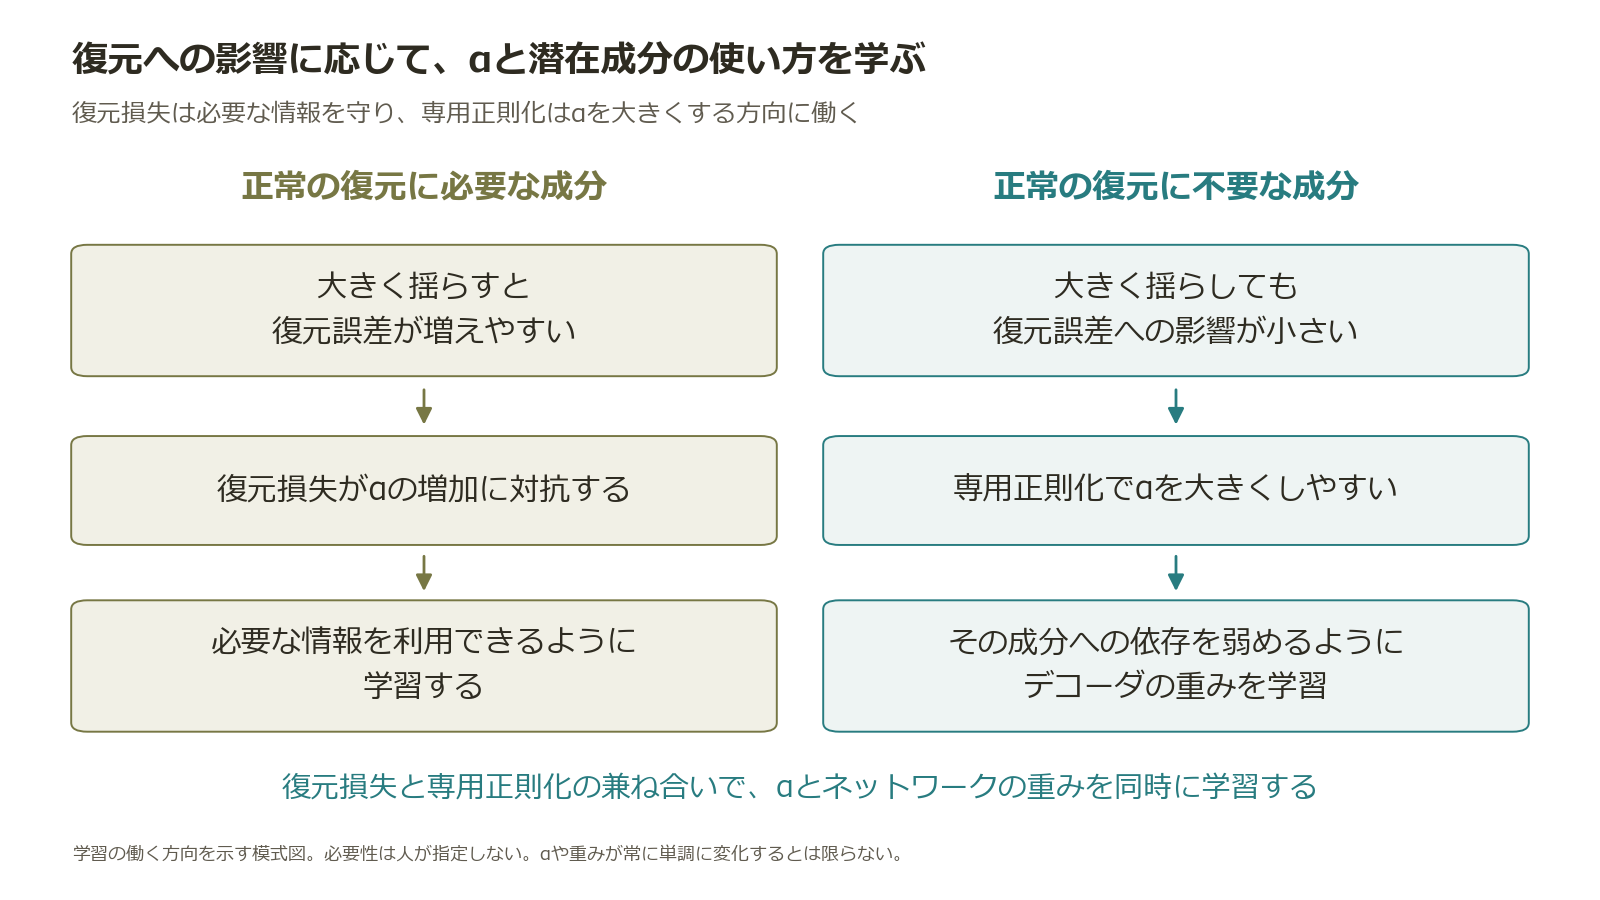

In [2]:
fig=plt.figure(figsize=(16,9),facecolor='white')
ax=fig.add_axes([0,0,1,1]);ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
fig.text(.045,.95,'復元への影響に応じて、αと潜在成分の使い方を学ぶ',fontsize=26,weight='bold',color=C['ink'],va='top')
fig.text(.045,.886,'復元損失は必要な情報を守り、専用正則化はαを大きくする方向に働く',fontsize=18,color=C['muted'],va='top')

def box(cx,cy,w,h,text,color,fill):
    ax.add_patch(FancyBboxPatch((cx-w/2,cy-h/2),w,h,boxstyle='round,pad=0.008,rounding_size=0.01',
                               linewidth=1.4,edgecolor=color,facecolor=fill))
    ax.text(cx,cy,text,ha='center',va='center',fontsize=22,color=C['ink'],linespacing=1.6)

def arrow(cx,top,bottom,color):
    ax.add_patch(FancyArrowPatch((cx,top),(cx,bottom),arrowstyle='-|>',mutation_scale=24,linewidth=2,color=color))

# 同じ「強く揺らす」という仮定から、復元への影響によって学習の圧力が異なることを比較。
for cx,color,fill,title,first,second,third in [
    (.265,C['olive'],C['sand'],'正常の復元に必要な成分',
     '大きく揺らすと\n復元誤差が増えやすい','復元損失がαの増加に対抗する',
     '必要な情報を利用できるように\n学習する'),
    (.735,C['teal'],C['pale'],'正常の復元に不要な成分',
     '大きく揺らしても\n復元誤差への影響が小さい','専用正則化でαを大きくしやすい',
     'その成分への依存を弱めるように\nデコーダの重みを学習')]:
    ax.text(cx,.79,title,ha='center',va='center',fontsize=24,weight='bold',color=color)
    box(cx,.655,.425,.13,first,color,fill)
    arrow(cx,.57,.525,color)
    box(cx,.455,.425,.105,second,color,fill)
    arrow(cx,.385,.34,color)
    box(cx,.26,.425,.13,third,color,fill)
fig.text(.5,.115,'復元損失と専用正則化の兼ね合いで、αとネットワークの重みを同時に学習する',
         ha='center',fontsize=21,color=C['teal'])
fig.text(.045,.045,'学習の働く方向を示す模式図。必要性は人が指定しない。αや重みが常に単調に変化するとは限らない。',
         fontsize=13,color=C['muted'])
fig.canvas.draw();renderer=fig.canvas.get_renderer();bounds=fig.bbox
for t in fig.findobj(matplotlib.text.Text):
    if not t.get_visible() or not t.get_text():continue
    b=t.get_window_extent(renderer)
    assert b.x0>=0 and b.y0>=0 and b.x1<=bounds.x1 and b.y1<=bounds.y1,t.get_text()
fig.savefig(OUT/(STEM+'.png'),dpi=200,transparent=False)
fig.savefig(OUT/(STEM+'.svg'),metadata={'Date':None,'Creator':'Sparse VAE conceptual explanation'})
p=OUT/(STEM+'.svg');p.write_text('\n'.join(line.rstrip() for line in p.read_text(encoding='utf-8').splitlines())+'\n',encoding='utf-8')
display(fig);plt.close(fig)

## 検証と説明上の注意

図は数値データや実測の依存度を含みません。ここでの検証は画像ファイルの生成と文字の収まりの確認です。理論については、次の限定付きで読みます。

- 「必要ならαが必ず下がる」「不要なら必ずαが上がる」という単調な変化の予測ではありません。
- 実際にはμ・α・デコーダが同時に変わり、情報の分担も変わる場合があります。
- 他の条件を固定した線形モデルでは、ノイズ由来の期待二乗誤差は $w^2\mu^2\alpha$ です。αが大きい成分に大きな重みwで依存すると、この負担が増えるという解説につながります。
- 正常を復元する要求とノイズを促す専用正則化の組合せで説明します。ノイズを加えるだけでSparse VAEになるわけではありません。

In [3]:
with Image.open(OUT/(STEM+'.png')) as im:
    assert im.size==(3200,1800)
    assert im.convert('RGB').getpixel((0,0))==(255,255,255)
ET.parse(OUT/(STEM+'.svg'))
print('PNG（3200×1800・白背景）、SVG、文字のキャンバス内配置：確認完了')
print('保存先:',OUT)
print('使用フォント:',FONT)

PNG（3200×1800・白背景）、SVG、文字のキャンバス内配置：確認完了
保存先: C:\Users\tokiy\my_GitHub\image-anomaly-detection\reports\sparse_vae_theory\figures
使用フォント: Meiryo
